# Hand dynamics

In the [Data](data.ipynb) tutorial, we fitted the `BoundedActor` and the `SubjectiveActor` to the tracking data of [Bonnen et al. (2015)](https://jov.arvojournals.org/article.aspx?articleid=2301260). In both models, the action directly sets the velocity of the cursor. Real hands cannot change their velocity instantaneously, though. In this tutorial, we fit two models with more realistic point-mass dynamics of the hand, the `PointMassBoundedActor` and the `PointMassSubjectiveActor`, and show that they explain the data better than their standard counterparts.

We follow the same steps as in the [Data](data.ipynb) tutorial, so we explain only what is new here.

**Note:** Fitting all models takes about 15 minutes on a laptop CPU.

In [1]:
import jax

# double precision makes the likelihood optimization numerically more stable
jax.config.update("jax_enable_x64", True)

import arviz as az
import jax.numpy as jnp
import matplotlib as mpl
import matplotlib.pyplot as plt
from jax import random

from lqg import xcorr
from lqg.io import load_tracking_data
from lqg.infer.mle import max_likelihood, Box, LogBox
from lqg.tracking import (
    BoundedActor,
    PointMassBoundedActor,
    PointMassSubjectiveActor,
    SubjectiveActor,
)

mpl.rcParams["axes.spines.right"] = False
mpl.rcParams["axes.spines.top"] = False

## Loading the data

We load the data as in the [Data](data.ipynb) tutorial and compute the cross-correlograms (CCGs) between target and cursor velocities, which we will compare with the models at the end.

In [2]:
data, blob_widths = load_tracking_data(data_path="../../data/")
data = jnp.asarray(data, dtype=jnp.float64)  # match the precision of the models

dt = 1 / 60.0  # the experiment ran at 60 Hz
colors = plt.cm.viridis(jnp.linspace(0, 0.9, len(blob_widths)))

vels = jnp.diff(data, axis=-2)
lags, correls = xcorr(vels[..., 1], vels[..., 0], maxlags=60)

## Standard models

As a baseline, we fit the `BoundedActor` and the `SubjectiveActor` with the same settings as in the [Data](data.ipynb) tutorial, which also explains the arguments of `max_likelihood` and the choice of bounds. We use the same number of restarts for all models in this tutorial.

In [3]:
fixed_params = {"dt": dt}  # parameters that are not estimated
num_restarts = 10  # random initializations of each fit, used for all models

bounded_constraints = {
    "action_cost": LogBox(low=1e-7, high=1e-2),
    "sigma_target": Box(low=0.01, high=100.0),
    "action_variability": Box(low=0.01, high=2.0),
    "sigma_cursor": Box(low=0.01, high=100.0),
}

subjective_constraints = {
    **bounded_constraints,
    "action_cost": LogBox(low=1e-7, high=1.0),
    "subj_noise": LogBox(low=1e-2, high=1e2),
    "subj_vel_noise": LogBox(low=1e-2, high=1e2),
}

key = random.PRNGKey(0)

bounded_params, subjective_params = [], []
for model_class, constraints, estimates in [
    (BoundedActor, bounded_constraints, bounded_params),
    (SubjectiveActor, subjective_constraints, subjective_params),
]:
    for x in data:
        key, subkey = random.split(key)
        params = max_likelihood(
            key=subkey,
            x=x,
            model=model_class,
            constraints=constraints,
            max_steps=1000,
            num_restarts=num_restarts,
            **fixed_params,
        )
        estimates.append(params)

## Point-mass hand dynamics

In the `BoundedActor` and the `SubjectiveActor`, the action directly sets the cursor velocity. The `PointMassBoundedActor` and the `PointMassSubjectiveActor` instead model the hand as a point mass driven by a muscle force with first-order dynamics (time constant `tau`), so the action changes the force, and the force accelerates the hand (see `lqg.tracking.point_mass` for the details). The state then contains the hand's velocity and force in addition to the target and cursor positions. Neither is observed in the data, but the likelihood takes care of this: it marginalizes over all state dimensions beyond the ones in `x`.

Apart from the dynamics, the two models are like their standard counterparts: The `PointMassSubjectiveActor` again has the two parameters `subj_noise` and `subj_vel_noise` of a subjective internal model of the target. The cost function now has extra terms for the hand's velocity (`velocity_cost`) and force (`force_cost`).

Two parameters need special treatment:

- We fix the muscle time constant to `tau = 0.066` s, a common value in the literature.
- We fix `force_cost = 0`. When it is estimated, it goes to its lower bound in almost all conditions, however small that bound is, so it does not help to explain the data. It also makes the optimization much slower.

Because the action now is a change in force rather than a velocity, `action_cost` and `action_variability` are on a different scale than in the standard models. The estimates of `action_cost` are several orders of magnitude smaller, so we give it a wide range on a log scale.

Fitting the point-mass models is slower than fitting the standard models, because their state has more dimensions and they have more parameters.

In [4]:
pm_fixed_params = {"dt": dt, "tau": 0.066, "force_cost": 0.0}

pm_bounded_constraints = {
    "action_cost": LogBox(low=1e-10, high=1.0),
    "velocity_cost": LogBox(low=1e-6, high=1.0),
    "sigma_target": Box(low=0.01, high=100.0),
    "sigma_cursor": Box(low=0.01, high=100.0),
    "action_variability": Box(low=0.01, high=10.0),
}

pm_subjective_constraints = {
    **pm_bounded_constraints,
    "subj_noise": LogBox(low=1e-2, high=1e2),
    "subj_vel_noise": LogBox(low=1e-2, high=1e2),
}

pm_bounded_params, pm_subjective_params = [], []
for model_class, constraints, estimates in [
    (PointMassBoundedActor, pm_bounded_constraints, pm_bounded_params),
    (PointMassSubjectiveActor, pm_subjective_constraints, pm_subjective_params),
]:
    for x in data:
        key, subkey = random.split(key)
        params = max_likelihood(
            key=subkey,
            x=x,
            model=model_class,
            constraints=constraints,
            max_steps=1000,
            num_restarts=num_restarts,
            **pm_fixed_params,
        )
        estimates.append(params)

{name: float(value) for name, value in pm_subjective_params[0].items()}

{'action_cost': 3.3888287277875605e-08,
 'action_variability': 2.027721829578542,
 'sigma_cursor': 5.000110372624759,
 'sigma_target': 5.961790204108106,
 'subj_noise': 3.2183361298146296,
 'subj_vel_noise': 0.2528663066274459,
 'velocity_cost': 0.00563831431515856}

To check the boundaries systematically, we compare all estimates with the bounds of their constraints:

In [5]:
def at_bounds(estimates, constraints, rtol=1e-3):
    # map -inf and +inf in unconstrained space to the lower and upper bounds
    flagged = []
    for condition, params in enumerate(estimates):
        for name, value in params.items():
            low = constraints[name].forward(-jnp.inf)
            high = constraints[name].forward(jnp.inf)
            # atol=0, otherwise every value below 1e-8 would count as close to the bound
            if jnp.isclose(value, low, rtol=rtol, atol=0) or jnp.isclose(value, high, rtol=rtol, atol=0):
                flagged.append((condition, name, float(value)))
    return flagged


print("BoundedActor:", at_bounds(bounded_params, bounded_constraints))
print("SubjectiveActor:", at_bounds(subjective_params, subjective_constraints))
print("PointMassBoundedActor:", at_bounds(pm_bounded_params, pm_bounded_constraints))
print("PointMassSubjectiveActor:", at_bounds(pm_subjective_params, pm_subjective_constraints))

BoundedActor: []
SubjectiveActor: [(4, 'subj_vel_noise', 0.010004215942594721)]
PointMassBoundedActor: []
PointMassSubjectiveActor: []


The only estimate at a boundary is `subj_vel_noise` of the `SubjectiveActor` at its *lower* bound in one condition. As discussed in the [Data](data.ipynb) tutorial, this means that the subjective velocity component does not help to explain the data in this condition.

## Model comparison

The models differ in their number of parameters: The subjective models have two more parameters than their bounded counterparts, and the point-mass models have one more (`velocity_cost`) than the standard ones. To compare the models fairly, we penalize the number of parameters with the Akaike information criterion, $\text{AIC} = 2k - 2 \log \hat{L}$, where lower is better. We report the AIC of each model relative to the `BoundedActor`.

In [6]:
T = data.shape[2] - 1  # number of transitions per trial

# model class, estimates, and fixed parameters of each model
models = {
    "BoundedActor": (BoundedActor, bounded_params, fixed_params),
    "SubjectiveActor": (SubjectiveActor, subjective_params, fixed_params),
    "PointMassBoundedActor": (PointMassBoundedActor, pm_bounded_params, pm_fixed_params),
    "PointMassSubjectiveActor": (PointMassSubjectiveActor, pm_subjective_params, pm_fixed_params),
}

aic = {}
for name, (model_class, estimates, fixed) in models.items():
    aic[name] = jnp.array(
        [
            2 * len(params) - 2 * model_class(**params, **fixed, T=T).log_likelihood(x).sum()
            for x, params in zip(data, estimates)
        ]
    )

delta_aic = {name: aic[name] - aic["BoundedActor"] for name in models}

print(f"{'Blob width':>10}" + "".join(f"{name:>26}" for name in models))
for i, width in enumerate(blob_widths):
    print(f"{width:10.0f}" + "".join(f"{delta_aic[name][i]:26.1f}" for name in models))

Blob width              BoundedActor           SubjectiveActor     PointMassBoundedActor  PointMassSubjectiveActor
        15                       0.0                   -1354.0                   -1460.1                   -1561.8
        17                       0.0                   -1084.5                   -1154.5                   -1220.8
        22                       0.0                    -813.2                    -733.8                    -889.5
        28                       0.0                    -636.5                    -600.8                    -725.1
        33                       0.0                    -554.6                    -517.9                    -722.7
        38                       0.0                    -782.0                    -587.5                    -994.0


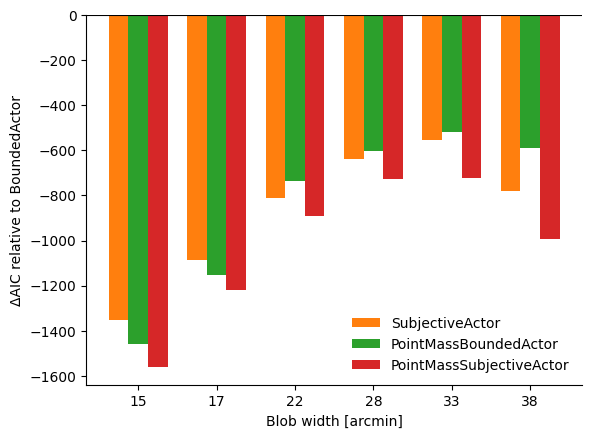

In [7]:
bar_width = 0.25
for i, name in enumerate(list(models)[1:]):
    plt.bar(jnp.arange(len(blob_widths)) + (i - 1) * bar_width, delta_aic[name], width=bar_width, color=f"C{i + 1}", label=name)
plt.xticks(jnp.arange(len(blob_widths)), [f"{w:.0f}" for w in blob_widths])
plt.axhline(0, color="k", linewidth=0.8)
plt.xlabel("Blob width [arcmin]")
plt.ylabel("ΔAIC relative to BoundedActor")
plt.legend(frameon=False)
plt.show()

Both extensions of the `BoundedActor` improve the fit in every condition, even after penalizing their additional parameters:

- The point-mass hand dynamics improve the fit of both the bounded and the subjective model. The `PointMassBoundedActor` beats the `BoundedActor` in every condition, and the `PointMassSubjectiveActor` beats the `SubjectiveActor` in every condition.
- The subjective internal model and the point-mass dynamics partly explain the same aspects of the data, so their improvements do not simply add up. Still, combining both helps: the `PointMassSubjectiveActor` has the lowest AIC in all conditions.

Which of the two extensions matters more depends on the condition: For small blob widths, the point-mass dynamics bring the larger improvement. For large blob widths, the subjective internal model does.

### Perceptual uncertainty

The parameter of main interest is the perceptual uncertainty about the target. It increases with blob width in all models, as expected. The only exception is the `PointMassSubjectiveActor` in the condition with the widest blob. The models agree on this trend but not on the absolute values: The point-mass models attribute more of the variability in the data to the motor system, so their estimates of `sigma_target` are smaller, at least for the smaller blob widths.

The exception at the widest blob suggests that `sigma_target` is not well constrained by these data in the `PointMassSubjectiveActor`: With more parameters, different combinations of them can explain the data almost equally well. A parameter recovery analysis (see below) can tell whether this is the case.

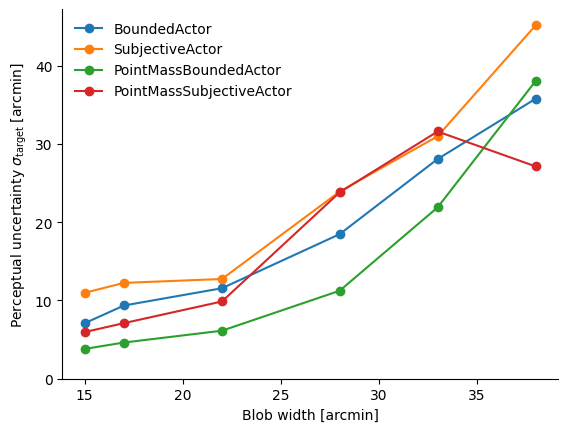

In [8]:
for name, (_, estimates, _) in models.items():
    plt.plot(blob_widths, [p["sigma_target"] for p in estimates], "o-", label=name)
plt.xlabel("Blob width [arcmin]")
plt.ylabel(r"Perceptual uncertainty $\sigma_\text{target}$ [arcmin]")
plt.ylim(0)
plt.legend(frameon=False)
plt.show()

### Simulating from the fitted models

To see how well the fitted models capture the data, we simulate cursor responses to the same target trajectories that the participants saw, using `simulate_actions`, and compute the CCGs of the simulated data. For the point-mass models, we pad the data with zeros for the hand velocity and force, which are simulated by the model, too.

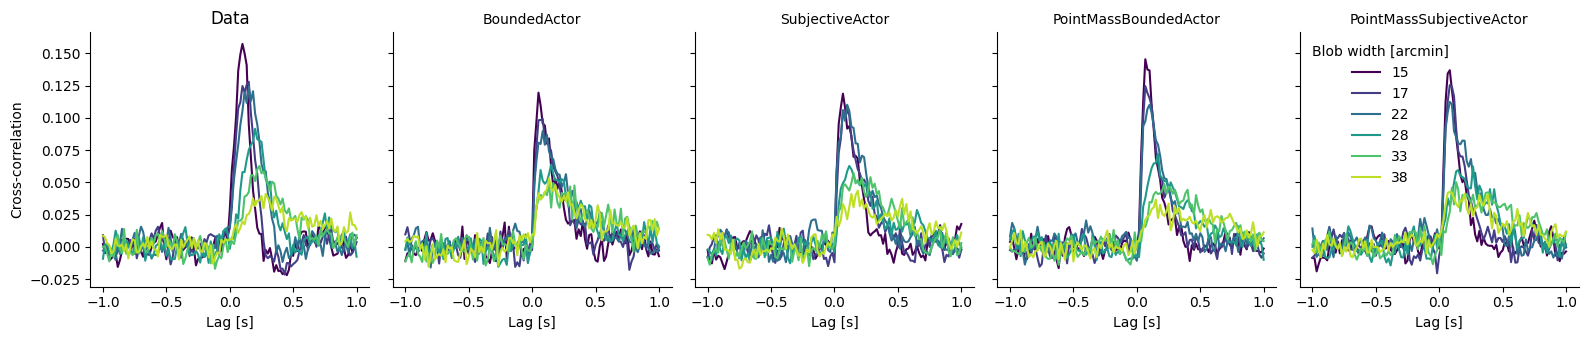

In [9]:
f, ax = plt.subplots(1, len(models) + 1, figsize=(16, 3.5), sharey=True, sharex=True)

ax[0].set_title("Data")
for color, c in zip(colors, correls.mean(axis=1)):
    ax[0].plot(lags * dt, c, color=color)

for a, (name, (model_class, estimates, fixed)) in zip(ax[1:], models.items()):
    for x, params, color, width in zip(data, estimates, colors, blob_widths):
        key, subkey = random.split(key)
        model = model_class(**params, **fixed, T=T)

        # pad the unobserved state dimensions with zeros, simulate everything except the target
        x_full = jnp.concatenate([x, jnp.zeros(x.shape[:-1] + (model.xdim - x.shape[-1],))], axis=-1)
        action_dim_mask = jnp.arange(model.xdim) > 0

        x_sim = model.simulate_actions(x_full, action_dim_mask, subkey)
        v = jnp.diff(x_sim, axis=-2)
        _, c = xcorr(v[..., 1], v[..., 0], maxlags=60)
        a.plot(lags * dt, c.mean(axis=0), color=color, label=f"{width:.0f}")
    a.set_title(name, fontsize="medium")

for a in ax:
    a.set_xlabel("Lag [s]")
ax[0].set_ylabel("Cross-correlation")
ax[-1].legend(title="Blob width [arcmin]", frameon=False)
f.tight_layout()
plt.show()

All models reproduce the qualitative pattern in the data: the CCG peaks get lower and broader with increasing blob width. The standard models produce peaks that are too low. The point-mass models capture the high, narrow peaks of the small blob widths much better, because the hand cannot change its velocity instantaneously. The simulated peaks are still slightly earlier than in the data, so even the best model does not capture every aspect of the behavior.

## Next steps

The point-mass models have more parameters, and some of them (for example `tau`) we fixed to values from the literature. To check whether the remaining parameters can be identified from data like these, run a parameter recovery analysis: simulate data from the model with known parameters, fit the model to the simulated data, and compare the estimates with the true values. `lqg.infer.mle.parameter_recovery` does this for any model class, and `python -m lqg.infer.mle` runs it from the command line.